In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [2]:
class ConvAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )
            
    def forward(self, x):
        latent_x = self.encoder(x)
        recon_x = self.decoder(latent_x)
        return recon_x
        
# Show output - instantiate the model and pretrained weights
conv_autoencoder = ConvAutoencoder()
conv_autoencoder.load_state_dict(torch.load("./models/mnist_autoencoder_weights.pth", weights_only=True))
print(conv_autoencoder)

ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(16, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (3): Sigmoid()
  )
)


In [3]:
test_data = datasets.MNIST(root="./data", 
                           train=False, 
                           download=True, 
                           transform=transforms.ToTensor())

test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

conv_autoencoder.eval()
batched_recons = []

with torch.no_grad():
    for x, _ in test_loader:
        recon_x = conv_autoencoder(x)
        batched_recons.append(recon_x)
        

all_recons = torch.cat(batched_recons, dim=0)

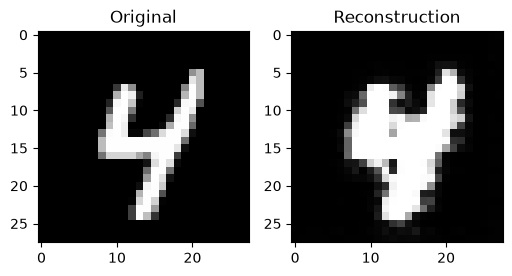

In [8]:
import matplotlib.pyplot as plt
%matplotlib inline

# Select first image in the current batch
idx = 3
original = x[idx, 0]
reconstruction = recon_x[idx, 0]

# Show output - visualize reconstructed image
def show_reconstruction(original, reconstruction):
    plt.figure(figsize=(6, 3))
    plt.subplot(1, 2, 1)
    plt.imshow(original, cmap="gray")
    plt.title("Original")

    plt.subplot(1, 2, 2)
    plt.imshow(reconstruction, cmap="gray")
    plt.title("Reconstruction")
    plt.show()

show_reconstruction(original, reconstruction)